First look at GAMs for this application. 

In [ ]:
import numpy as np
import pandas as pd
from pygam import LinearGAM, s
from functools import reduce
from matplotlib import pyplot as plt

In [ ]:
## reading in stata file
df = pd.read_stata("data/raw/brexitevote-ep2017.dta")
df = df[df["Pct_Leave"].notna()].rename(columns={"code": "Area_Code"}).reset_index(drop=True)
print(f"Loaded {len(df)} GB Local Authority Districts")
df.head()
print(len(df.columns))
print(df.columns)
assert len(df) == 380 # check from conor's code earlier

In [ ]:
df.columns[15:25]
# for the first look at GAMs, I'll look only at the first 10 columns of demographic/economic/social data (since we have 110 columns in total. The first 15 columns have to do with the referendum results, so there isn't any causality)

Will use "Pct_Leave" as the outcome variable. I'll define the columns in case the indicies change. 

In [ ]:
features = [
    "pensionergrowth20012011", "ResidentAge30to44share", "ResidentAge45to59share",
    "ResidentAge60plusshare", "median_hourly_pay2005", "median_hourly_pay_growth",
    "mean_hourly_pay2005", "mean_hourly_pay_growth", "iqrpay2005", "EU_2001Migrantshare",
]

data = df[features + ["Pct_Leave"]].dropna()   # drops rows missing X *or* y
X = data[features].to_numpy()
y = data["Pct_Leave"].to_numpy()

# One smooth term per feature: s(0) + s(1) + ... + s(9)
terms = reduce(lambda a, b: a + b, [s(i, n_splines=10) for i in range(len(features))])

# gridsearch picks the smoothing penalty (lam) for you
gam = LinearGAM(terms).gridsearch(X, y, lam=np.logspace(-3, 3, 11))
gam.summary()

# Partial dependence plot for each variable
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, ax in enumerate(axes.flat):
    XX = gam.generate_X_grid(term=i)
    pdep, ci = gam.partial_dependence(term=i, X=XX, width=0.95)
    ax.plot(XX[:, i], pdep)
    ax.plot(XX[:, i], ci, "r--", alpha=0.5)
    ax.set_title(features[i], fontsize=9)
plt.tight_layout()

In [ ]:
df.columns[15:55]

In [56]:
more_features = ['pensionergrowth20012011', 'ResidentAge30to44share',
       'ResidentAge45to59share', 'ResidentAge60plusshare',
       'median_hourly_pay2005', 'median_hourly_pay_growth',
       'mean_hourly_pay2005', 'mean_hourly_pay_growth', 'iqrpay2005',
       'EU_2001Migrantshare', 'NONEU_2001Migrantshare', 'EU_Migrantgrowth',
       'NONEU_Migrantgrowth', 'unqualifiedsharechange',
       'self_employment_rate_aps', 'umemployment_rate_aps',
       'economic_activity_rate_aps2015', 'MEP_Turnout', 'MEP_ConPct',
       'MEP_LabPct', 'MEP_LDPct', 'MEP_UKIPPct', 'MEP_GreenPct', 'MEP_BNPPct',
       'Total_EconomyEU_dependence', 'TotalImpactFLWAAYR',
       'TREATED_WITHIN_62_DAYS', 'PRCP_AMT22', 'PRCP_AMT23', 'life_sat_mean',
       'life_sat_cv', 'BREXITINDEXNARROW', 'noqual_2001_sh', 'quall1_2001_sh',
       'quall2_2001_sh', 'quall3_2001_sh', 'quall4plus_2001_sh',
       'noqual_sh_growth', 'quall1_sh_growth', 'quall2_sh_growth']

conflicts = ['BREXITINDEXNARROW', 'MEP_Turnout', 'MEP_ConPct',
       'MEP_LabPct', 'MEP_LDPct', 'MEP_UKIPPct', 'MEP_GreenPct', 'MEP_BNPPct', 'iqrpay2005', 'mean_hourly_pay2005']

more_features = [f for f in more_features if f not in conflicts]

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
  9% (1 of 11) |##                       | Elapsed Time: 0:00:00 ETA:   0:00:16
 18% (2 of 11) |####                     | Elapsed Time: 0:00:01 ETA:   0:00:09
 27% (3 of 11) |######                   | Elapsed Time: 0:00:02 ETA:   0:00:08
 36% (4 of 11) |#########                | Elapsed Time: 0:00:03 ETA:   0:00:06
 45% (5 of 11) |###########              | Elapsed Time: 0:00:03 ETA:   0:00:05
 54% (6 of 11) |#############            | Elapsed Time: 0:00:04 ETA:   0:00:04
 63% (7 of 11) |###############          | Elapsed Time: 0:00:04 ETA:   0:00:03
 72% (8 of 11) |##################       | Elapsed Time: 0:00:06 ETA:   0:00:02
 81% (9 of 11) |####################     | Elapsed Time: 0:00:06 ETA:   0:00:01
 90% (10 of 11) |#####################   | Elapsed Time: 0:00:07 ETA:   0:00:00
100% (11 of 11) |########################| Elapsed Time: 0:00:08 Time:  0:00:08
/var/folders/6x/97szp2r1767db1mhfj2yzckm

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     58.0361
Link Function:                     IdentityLink Log Likelihood:                                  -903.9638
Number of Samples:                          372 AIC:                                             1925.9998
                                                AICc:                                            1948.7223
                                                GCV:                                               12.1996
                                                Scale:                                              2.9715
                                                Pseudo R-Squared:                                   0.9309
Feature Function                  Lam

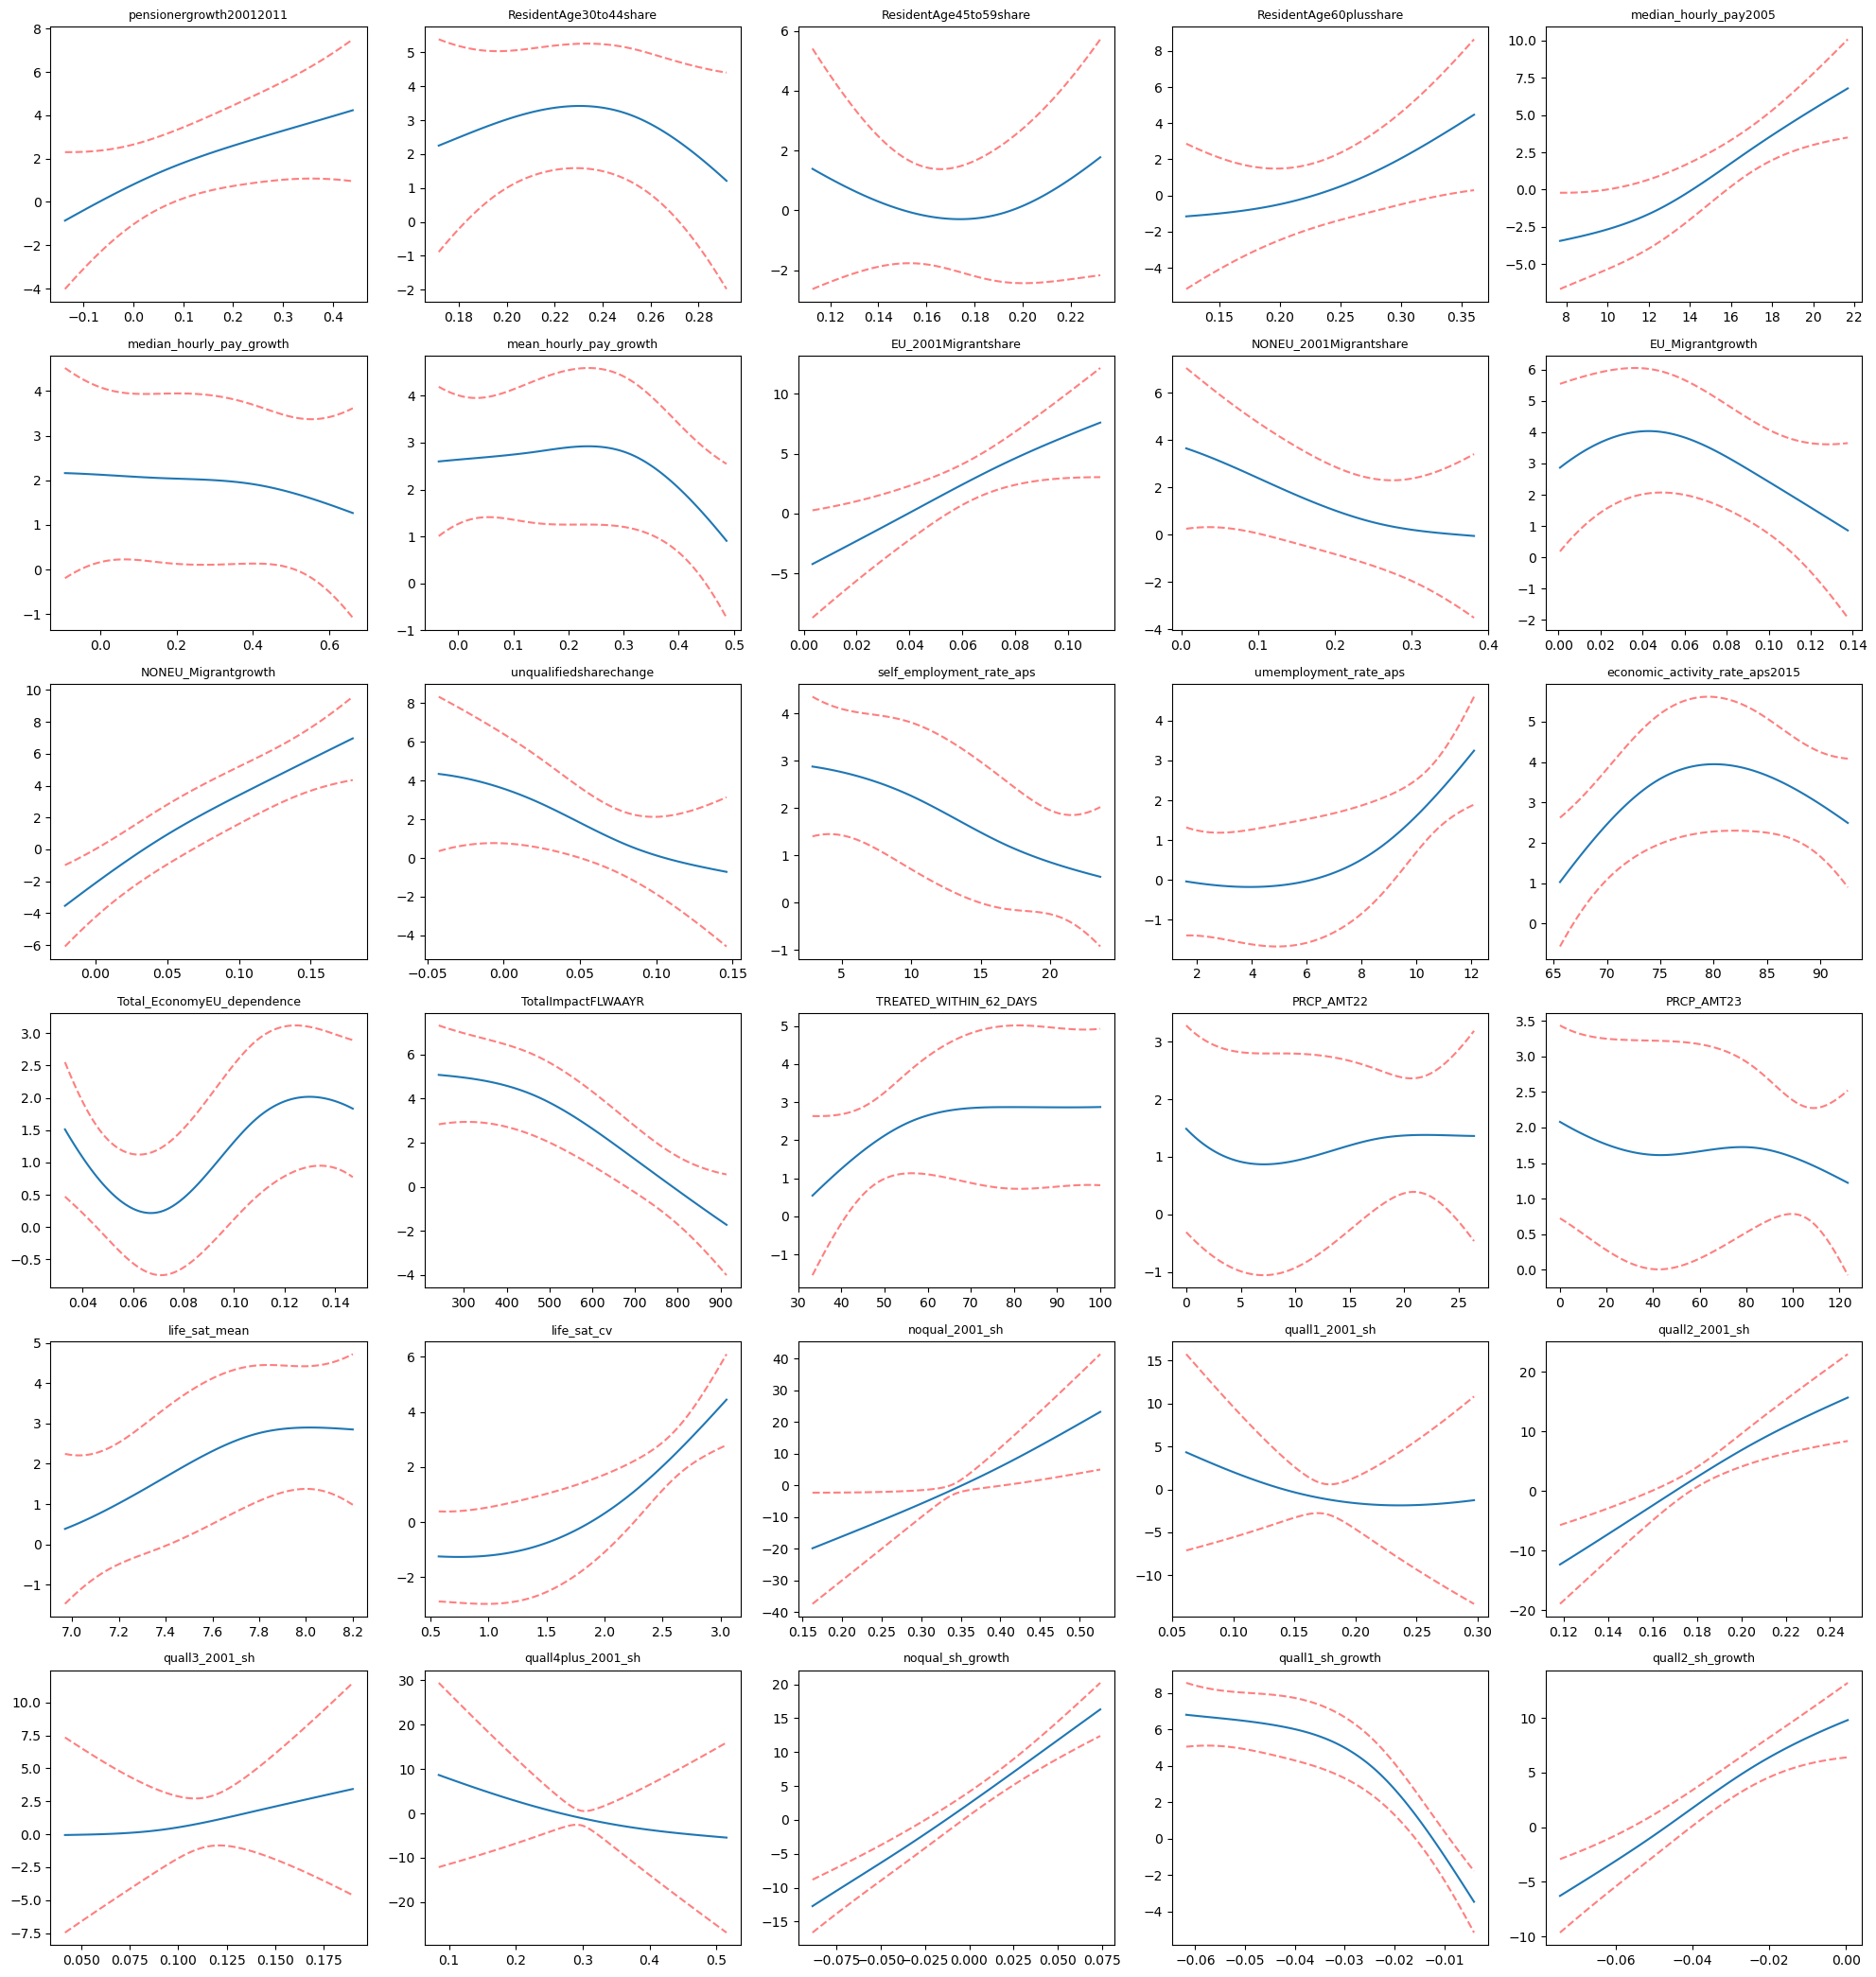

In [57]:
data = df[more_features + ["Pct_Leave"]].dropna()   # drops rows missing X *or* y
X = data[more_features].to_numpy()
y = data["Pct_Leave"].to_numpy()

# One  term per feature
terms = reduce(lambda a, b: a + b, [s(i, n_splines=6) for i in range(len(more_features))])

# gridsearch picks the smoothing penalty (lam) for you
gam = LinearGAM(terms).gridsearch(X, y, lam=np.logspace(-3, 3, 11))
gam.summary()

# Partial dependence plot for each variable
n = len(more_features)
ncols = 5
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)

for i, ax in enumerate(axes.flat):
    if i >= n:
        ax.set_visible(False)   # hide any empty panels
        continue
    XX = gam.generate_X_grid(term=i)
    pdep, ci = gam.partial_dependence(term=i, X=XX, width=0.95)
    ax.plot(XX[:, i], pdep)
    ax.plot(XX[:, i], ci, "r--", alpha=0.5)
    ax.set_title(more_features[i], fontsize=9)
plt.tight_layout()

In [ ]:
from pygam import LogisticGAM

# 1 = majority Leave, 0 = majority Remain
df["Leave_majority"] = (df["Pct_Leave"] > 50).astype(float)
df.loc[df["Pct_Leave"].isna(), "Leave_majority"] = np.nan   # keep missing as missing

data = df[more_features + ["Leave_majority"]].dropna()
X = data[more_features].to_numpy()
y = data["Leave_majority"].to_numpy()

terms = reduce(lambda a, b: a + b, [s(i, n_splines=6) for i in range(len(more_features))])
lgam = LogisticGAM(terms).gridsearch(X, y, lam=np.logspace(-3, 3, 11))
lgam.summary()
print("Accuracy:", lgam.accuracy(X, y))

In [ ]:
n = len(more_features)
ncols = 5
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)

for i, ax in enumerate(axes.flat):
    if i >= n:
        ax.set_visible(False)   # hide any empty panels
        continue
    XX = lgam.generate_X_grid(term=i)
    pdep, ci = lgam.partial_dependence(term=i, X=XX, width=0.95)
    ax.plot(XX[:, i], pdep)
    ax.plot(XX[:, i], ci, "r--", alpha=0.5)
    ax.set_title(more_features[i], fontsize=9)
plt.tight_layout()


In [55]:
## Looking to find the best covariates. Results from the GAM suggested that our covariates in more_variables are highly correlated, so it makes the model difficult to interpret. 
corr = df[more_features].corr()

# keep each pair once (upper triangle only, no diagonal)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = (corr.where(mask).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "var1", "level_1": "var2"}))

high = pairs[pairs["corr"].abs() > 0.8].sort_values("corr", key=abs, ascending=False)
print(high.to_string(index=False))

                  var1                   var2      corr
   mean_hourly_pay2005             iqrpay2005  0.950261
 median_hourly_pay2005    mean_hourly_pay2005  0.942425
 median_hourly_pay2005             iqrpay2005  0.898059
        noqual_2001_sh     quall4plus_2001_sh -0.855531
ResidentAge30to44share ResidentAge60plusshare -0.841491
